# Wyzwanie 1 – ML: wpływ learning rate na klasyfikację viralowych filmów

Pobieram moje dane dotyczące filmików z youTuba. Mój model będzie przewidywał czy filmik jest viralem czy nie.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

videos_df = pd.read_csv('viral_videos.csv', index_col='video_id')
print(videos_df.head())

           category  duration_sec  title_length  thumbnail_face  upload_hour  \
video_id                                                                       
vid_000001   Beauty           517            64               1           23   
vid_000002     Tech           495            47               1           23   
vid_000003   Beauty           311            76               0           17   
vid_000004  Fitness           590            69               0            0   
vid_000005     Tech           380            58               1           19   

           upload_day  tags_count  description_length  subscriber_count  \
video_id                                                                  
vid_000001        Wed          27                 429            907474   
vid_000002        Mon          10                 222           1004641   
vid_000003        Mon          13                 520            168170   
vid_000004        Mon          17                 309           

Pooglądam sobie te dane i zrobię parę wykresów.

### **1. Przygotowanie danych.**

Utowrzę kopię tej listy, żeby móc potem ładniej zobrazować zależności

In [160]:
videos_df_copy=videos_df.copy()

Zobaczmy czy są jakieś puste wartości, które mogłyby zaburzyć działanie modelu

In [161]:
videos_df.isna().sum()

category              0
duration_sec          0
title_length          0
thumbnail_face        0
upload_hour           0
upload_day            0
tags_count            0
description_length    0
subscriber_count      0
views                 0
likes                 0
comments              0
shares                0
viral                 0
dtype: int64

Nie ma wartości pustych :)

In [162]:
videos_df.dtypes

category                str
duration_sec          int64
title_length          int64
thumbnail_face        int64
upload_hour           int64
upload_day              str
tags_count            int64
description_length    int64
subscriber_count      int64
views                 int64
likes                 int64
comments              int64
shares                int64
viral                 int64
dtype: object

Kolumny category i upload_day zawierają dane kategorialne, więc zakoduje je metodą One-Hot Encoding

In [163]:
#videos_df = pd.DataFrame({"category":[ x for x in videos_df['category'].str[0].unique()]})
videos_df= pd.get_dummies(videos_df, columns=['category'], dtype=int)
videos_df= pd.get_dummies(videos_df, columns=['upload_day'], dtype=int)
print(videos_df.iloc[:,-20:].head())


            category_Cooking  category_DIY  category_Education  \
video_id                                                         
vid_000001                 0             0                   0   
vid_000002                 0             0                   0   
vid_000003                 0             0                   0   
vid_000004                 0             0                   0   
vid_000005                 0             0                   0   

            category_Finance  category_Fitness  category_Gaming  \
video_id                                                          
vid_000001                 0                 0                0   
vid_000002                 0                 0                0   
vid_000003                 0                 0                0   
vid_000004                 0                 1                0   
vid_000005                 0                 0                0   

            category_Music  category_News  category_Science  catego

Przeanalizuje teraz skrajne wartości:

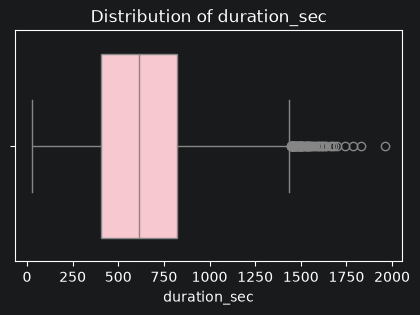

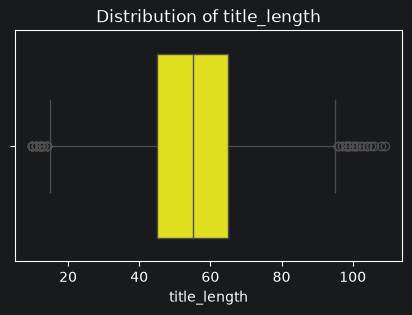

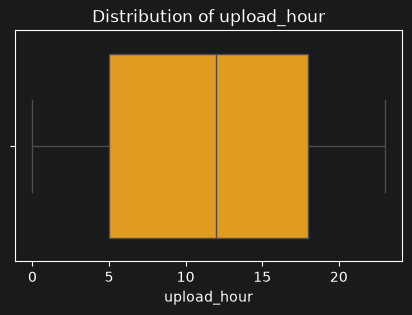

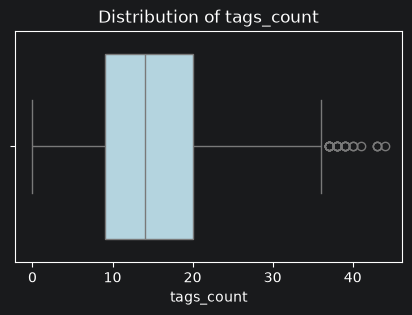

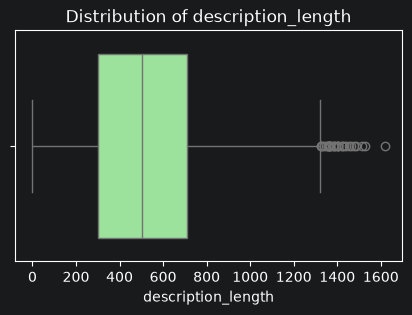

In [164]:
def Boxplot(feature, color):
    plt.figure(figsize=(5, 3))
    sns.boxplot(x=videos_df[feature].dropna(), color=color)
    plt.title('Distribution of ' + feature)
    plt.xlabel(feature)
    plt.show()


Boxplot('duration_sec', 'pink')
Boxplot('title_length', 'yellow')
Boxplot('upload_hour', 'orange')
Boxplot('tags_count', 'lightblue')
Boxplot('description_length', 'lightgreen')


Zauważmy, że duration_sec ma bardzo zozłożone wartości. Jednak wartości skrajne (2000s to ok. 33min) są prawdopodobne i raczej nie są błędem w danych. Tak samo sytuacja dotyczy title_length, tags_cound i description_lenght. Widać ktoś wstawia filmiki z długim (najdłuższy to ok. 1600 znaków, czyli pół strony  A4) opisem ale nie są to wartości niepokojące. Również dane z  godzinami w ciągu dnia mieszczą się w przedziale 0 - 24. (Co jest dobre, bo doba ma 24 godziny :))


### **2. Wykresy**



Zobaczmy, jak wygląda rozkład danych (czy filmiki jest viralem).


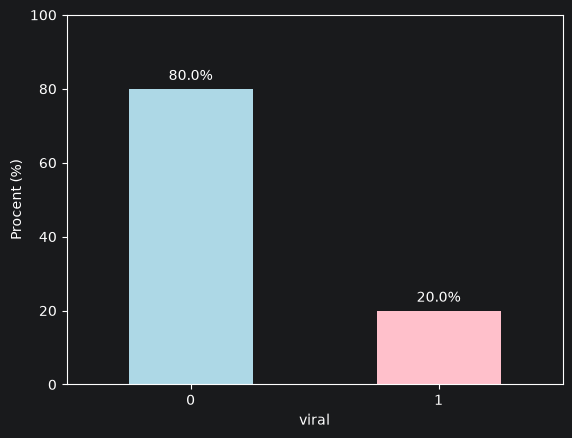

In [165]:
procenty = videos_df["viral"].value_counts(normalize=True).sort_index() * 100

ax = procenty.plot.bar(color=["lightblue", "pink"])
ax.bar_label(ax.containers[0],fmt="%.1f%%", padding=4)

plt.ylabel("Procent (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()

Jest to logiczne, ponieważ viral został określony jako filmik w top 20% wyświetleń. Zatem kolumna views jest bezprośrednio skorelowana z kolumną viral, więc model mógłby po prostu odkryć ten schemat, co byłoby ogromnym data leakage!!!
 Przy tworzeniu modelu będę musiała wziąć pod uwagę niezbalansowanie klas.

Zobaczmy teraz macierz korelacji.

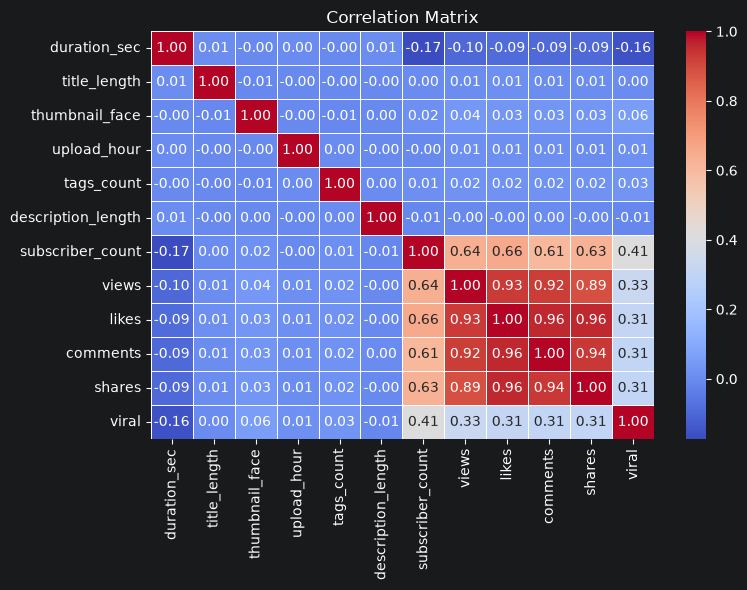

In [166]:
data = videos_df.iloc[:, 0:12]

plt.figure(figsize=(8,6))
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

Jedyne silne korelacje liniowe istnieją między ilością lajków, komentarzy, udostępnień i liczby wyświetleń. Jest to logiczne. Trzeba będzie jednak te kolumny usunąć, ponieważ są to informacje zebrane po ustaleniu, czy film jest viralem, więc znając te informacje, praktycznie podaję modelowi na tacy rozwiązanie (data leakage). **Duża jest też korelacja z subscriber_count?????????????**

In [167]:
videos_df = videos_df.drop(columns=["views", "likes", "comments", "shares"])

Osobno stworzę wykres, żeby zobaczyć zależność danej kategorii od viralowości.

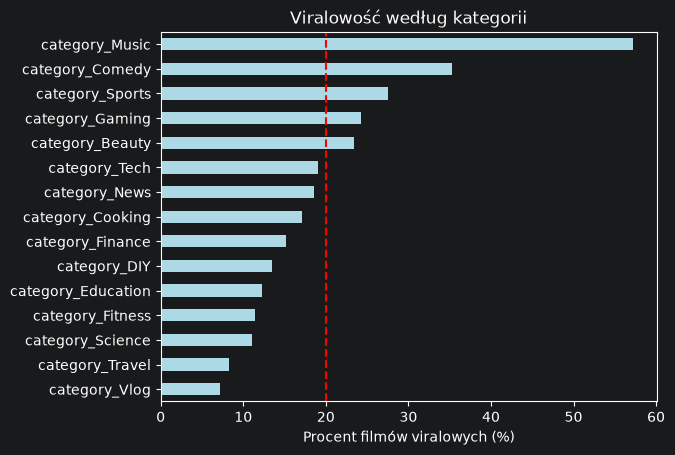

In [168]:
kategorie = videos_df.filter(like="category_")

procenty = ((kategorie[videos_df["viral"] == 1].sum() / kategorie.sum()) * 100
)

procenty.sort_values().plot.barh(color="lightblue")

plt.xlabel("Procent filmów viralowych (%)")
plt.title("Viralowość według kategorii")
plt.axvline(20, color="red", linestyle="--")
plt.show()

WOW! niesamowite wyniki. Okazuje się, że filmy muzyczne dużo częściej zostają viralem.

Podobny wykres stwórzmy do dni tygodnia:


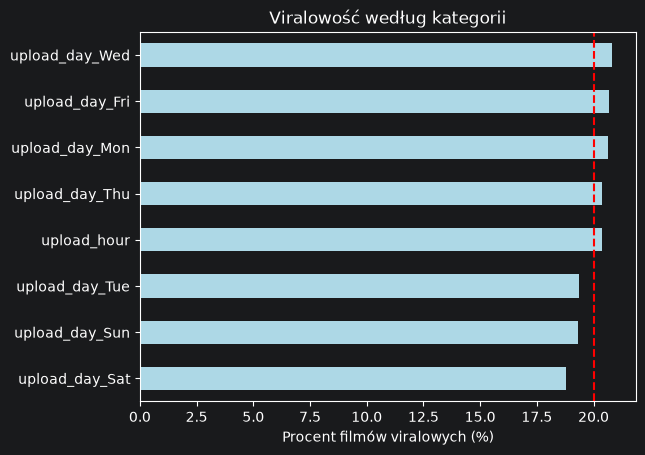

In [169]:
kategorie = videos_df.filter(like="upload_")

procenty = ((kategorie[videos_df["viral"] == 1].sum() / kategorie.sum()) * 100
)

procenty.sort_values().plot.barh(color="lightblue")

plt.xlabel("Procent filmów viralowych (%)")
plt.title("Viralowość według kategorii")
plt.axvline(20, color="red", linestyle="--")
plt.show()

Wyniki wykresu wskazują, że dni tygodnia mają bardzo mały wpływ na viralowość filmu. Wszystkie dni tygodnia nie różnią się o więcej niż 2 punkty procentowe względem średniej.

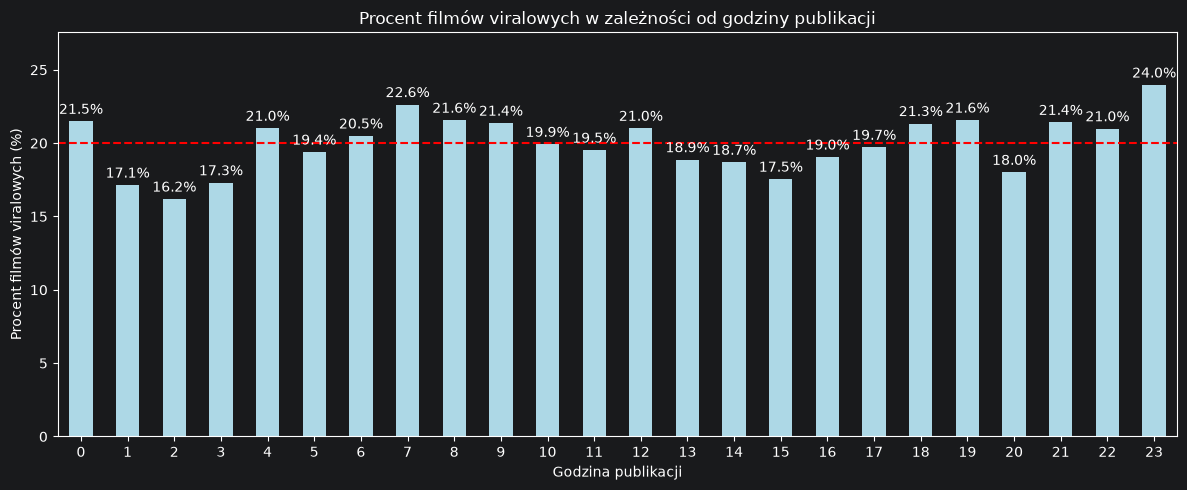

In [170]:
procenty = videos_df.groupby("upload_hour")["viral"].mean() * 100

ax = procenty.plot(kind="bar", figsize=(12, 5), color="lightblue")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

plt.axhline(20, color="red", linestyle="--")
plt.xlabel("Godzina publikacji")
plt.ylabel("Procent filmów viralowych (%)")
plt.title("Procent filmów viralowych w zależności od godziny publikacji")
plt.xticks(rotation=0)
plt.ylim(0, max(25, procenty.max() * 1.15))
plt.tight_layout()
plt.show()

In [171]:
videos_df.head()

,duration_sec,title_length,thumbnail_face,upload_hour,tags_count,description_length,subscriber_count,viral,category_Beauty,category_Comedy,...,category_Tech,category_Travel,category_Vlog,upload_day_Fri,upload_day_Mon,upload_day_Sat,upload_day_Sun,upload_day_Thu,upload_day_Tue,upload_day_Wed
video_id,,,,,,,,,,,,,,,,,,,,,
vid_000001,517,64,1,23,27,429,907474,1,1,0,...,0,0,0,0,0,0,0,0,0,1
vid_000002,495,47,1,23,10,222,1004641,0,0,0,...,1,0,0,0,1,0,0,0,0,0
vid_000003,311,76,0,17,13,520,168170,0,1,0,...,0,0,0,0,1,0,0,0,0,0
vid_000004,590,69,0,0,17,309,285593,0,0,0,...,0,0,0,0,1,0,0,0,0,0
vid_000005,380,58,1,19,0,101,1073326,1,0,0,...,1,0,0,0,1,0,0,0,0,0


In [173]:
clean_videos_df=videos_df.copy()
clean_videos_df.to_csv("videos_clean.csv", index=False)